## Carga de librerias e importación dataset

### Pipeline principal

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
import pickle

def logit(p):
    return np.log(p / (1 - p))


def cllr(lr, y):
    lr = np.asarray(lr, dtype=float)
    y = np.asarray(y)
    tp = (np.mean(np.log2(1 + 1 / lr[y == 1]))
        if (y == 1).any()
        else 0)

    td = (np.mean(np.log2(1 + lr[y == 0]))
        if (y == 0).any()
        else 0)

    return 0.5 * (tp + td)


def construir_lr_historico(resultados_df, fecha_corte_calib_test=pd.Timestamp("2019-01-01")):
    """
    Ajusta Platt con el pool de calibración y aplica ese mismo
    calibrador a todos los scores OOS históricos.

    Devuelve un dataframe con log_LR y LR.
    """

    resultados_df = resultados_df.copy()
    resultados_df["TX_DATETIME"] = pd.to_datetime(resultados_df["TX_DATETIME"])

    # Pool de calibración
    calib_df = resultados_df[resultados_df["TX_DATETIME"] <= fecha_corte_calib_test].copy()
    prior_calib = calib_df["TX_FRAUD"].mean()

    # Platt
    platt = LogisticRegression()
    platt.fit(calib_df["raw_score"].values.reshape(-1, 1), calib_df["TX_FRAUD"].values)
    beta0 = platt.intercept_[0]
    beta1 = platt.coef_[0][0]

    # LR histórico
    historico_df = resultados_df.copy()
    log_odds = (beta0 + beta1 * historico_df["raw_score"].values)

    historico_df["log_LR"] = (log_odds - logit(prior_calib))
    historico_df["LR"] = np.exp(np.clip(historico_df["log_LR"], -700, 700))

    return historico_df


def construir_cllr_historico(historico_df, ventana_cllr=7):
    
    historico_df = historico_df.copy()
    historico_df["TX_DATETIME"] = pd.to_datetime(historico_df["TX_DATETIME"])

    lr = historico_df["LR"].values
    y = historico_df["TX_FRAUD"].values

    es_fraude = (y == 1)
    es_legit = (y == 0)

    termino_fraude = np.where(es_fraude, np.log2(1 + 1 / lr), 0.0)
    termino_legit = np.where(es_legit, np.log2(1 + lr), 0.0)

    tmp = pd.DataFrame({
        "TX_DATETIME": historico_df["TX_DATETIME"].values,
        "termino_fraude": termino_fraude,
        "termino_legit": termino_legit,
        "es_fraude": es_fraude.astype(int),
        "es_legit": es_legit.astype(int),
    })

    diario = (
        tmp.groupby("TX_DATETIME")
        .agg(
            suma_termino_fraude=("termino_fraude", "sum"),
            suma_termino_legit=("termino_legit", "sum"),
            n_fraude=("es_fraude", "sum"),
            n_legit=("es_legit", "sum"),
        )
        .sort_index()
    )

    rango_completo = pd.date_range(diario.index.min(), diario.index.max(), freq="D")
    diario = diario.reindex(rango_completo, fill_value=0)
    diario.index.name = "TX_DATETIME"

    roll = diario.rolling(window=ventana_cllr, min_periods=1).sum()

    n_obs = roll["n_fraude"] + roll["n_legit"]

    with np.errstate(invalid="ignore", divide="ignore"):
        cllr_fraude = roll["suma_termino_fraude"] / roll["n_fraude"]
        cllr_legit = roll["suma_termino_legit"] / roll["n_legit"]

    valor_cllr = 0.5 * (cllr_fraude + cllr_legit)
    valor_cllr = valor_cllr.where((roll["n_fraude"] > 0) & (roll["n_legit"] > 0))

    return pd.DataFrame({
        "TX_DATETIME": roll.index,
        "CLLR_7D": valor_cllr.values,
        "N_OBS_7D": n_obs.values.astype(int),
        "N_FRAUDES_7D": roll["n_fraude"].values.astype(int),
        "PRIOR_7D": (roll["n_fraude"] / n_obs).values,
    }).reset_index(drop=True)

In [ ]:
# LR con switching gradual de escenarios por período.

import pandas as pd
import numpy as np
import warnings

from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

RUTA_ARCHIVO_PARQUET = (
    '/Users/ceciliaguillametchargue/Tesis/'
    'Tesis_MGADO/simulated-data/calibracion')

ARCHIVO = 'transactions_all_run1.parquet'

VENTANA = 30
RUN_SEED = 42

FECHA_CORTE_CALIB_TEST = pd.Timestamp('2019-01-01')


df = pd.read_parquet(f'{RUTA_ARCHIVO_PARQUET}/{ARCHIVO}')

label_encoder_customer = LabelEncoder()
label_encoder_terminal = LabelEncoder()

df['CUSTOMER_ID'] = label_encoder_customer.fit_transform(df['CUSTOMER_ID'])
df['TERMINAL_ID'] = label_encoder_terminal.fit_transform(df['TERMINAL_ID'])

df['TX_DATETIME'] = pd.to_datetime(df['TX_DATETIME'])
df['TX_TIME'] = df['TX_DATETIME'].dt.hour
df['TX_DAY_WEEK'] = df['TX_DATETIME'].dt.weekday
df['TX_DATETIME'] = df['TX_DATETIME'].dt.normalize()

df = df[df['TX_FRAUD_SCENARIO'] != 1].copy()


# CAMBIO GRADUAL DE ESCENARIOS

FECHA_CORTE_1 = pd.Timestamp('2018-06-30')
FECHA_INICIO_TRANSICION_1 = pd.Timestamp('2018-06-01')
FECHA_CORTE_2 = pd.Timestamp('2018-09-30')
FECHA_INICIO_TRANSICION_2 = pd.Timestamp('2018-09-01')
FECHA_CORTE_3 = pd.Timestamp('2018-12-31')
FECHA_INICIO_TRANSICION_3 = pd.Timestamp('2018-12-01')


condicion_periodo_1 = ((df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_1) & (df['TX_FRAUD_SCENARIO'].isin([0, 2])))
condicion_transicion_1 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_1) & (df['TX_DATETIME'] <= FECHA_CORTE_1) & (df['TX_FRAUD_SCENARIO'].isin([0, 2, 3])))
condicion_periodo_2 = ((df['TX_DATETIME'] > FECHA_CORTE_1) & (df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_2) & (df['TX_FRAUD_SCENARIO'].isin([0, 3])))
condicion_transicion_2 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_2) & (df['TX_DATETIME'] <= FECHA_CORTE_2) & (df['TX_FRAUD_SCENARIO'].isin([0, 2, 3])))
condicion_periodo_3 = ((df['TX_DATETIME'] > FECHA_CORTE_2) & (df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_3) & (df['TX_FRAUD_SCENARIO'].isin([0, 2])))
condicion_transicion_3 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_3) & (df['TX_DATETIME'] <= FECHA_CORTE_3) & (df['TX_FRAUD_SCENARIO'].isin([0, 2, 3])))
condicion_periodo_4 = ((df['TX_DATETIME'] > FECHA_CORTE_3) & (df['TX_FRAUD_SCENARIO'].isin([0, 3])))


condicion_final = (
    condicion_periodo_1 | 
    condicion_transicion_1 | 
    condicion_periodo_2 | 
    condicion_transicion_2 | 
    condicion_periodo_3 | 
    condicion_transicion_3 | 
    condicion_periodo_4)

df = df[condicion_final].copy()

# CREAR IDENTIFICACIÓN DEL RÉGIMEN

def identificar_regimen(fecha):
    if fecha <= FECHA_INICIO_TRANSICION_1:
        return 'periodo_1'
    elif fecha <= FECHA_CORTE_1:
        return 'transicion_1'
    elif fecha <= FECHA_INICIO_TRANSICION_2:
        return 'periodo_2'
    elif fecha <= FECHA_CORTE_2:
        return 'transicion_2'
    elif fecha <= FECHA_INICIO_TRANSICION_3:
        return 'periodo_3'
    elif fecha <= FECHA_CORTE_3:
        return 'transicion_3'
    else:
        return 'periodo_4'


df['REGIMEN'] = df['TX_DATETIME'].apply(identificar_regimen)

# Indicador sencillo de transición
df['ES_TRANSICION'] = df['REGIMEN'].str.startswith('transicion')


# FEATURES DE VENTANA MÓVIL

df = df.sort_values(by=['CUSTOMER_ID', 'TX_DATETIME'])

daily_spending = (
    df.groupby(['CUSTOMER_ID', 'TX_DATETIME'])['TX_AMOUNT']
    .agg(TX_AMOUNT_DAILY='sum', TX_CNT_DAILY='count').reset_index())


for window in [3, 7, 30]:

    daily_spending[f'TX_AMOUNT_{window}D'] = (
        daily_spending
        .groupby('CUSTOMER_ID')['TX_AMOUNT_DAILY']
        .rolling(window=window, min_periods=1).sum().reset_index(level=0, drop=True))

    daily_spending[f'MOV_AVG_TX_AMOUNT_{window}D'] = (
        daily_spending
        .groupby('CUSTOMER_ID')['TX_AMOUNT_DAILY']
        .rolling(window=window, min_periods=1).mean().reset_index(level=0, drop=True))

    daily_spending[f'TX_CNT_{window}D'] = (
        daily_spending
        .groupby('CUSTOMER_ID')['TX_CNT_DAILY']
        .rolling(window=window, min_periods=1).sum().reset_index(level=0, drop=True))

    daily_spending[f'TX_STD_AMOUNT_{window}D'] = (
        daily_spending
        .groupby('CUSTOMER_ID')['TX_AMOUNT_DAILY']
        .rolling(window=window, min_periods=1).std().reset_index(level=0, drop=True))

daily_spending['VAR_TX_AMOUNT_1D'] = (daily_spending.groupby('CUSTOMER_ID')['TX_AMOUNT_DAILY'].diff())
df = df.merge(daily_spending, on=['CUSTOMER_ID', 'TX_DATETIME'], how='left')


# WALK-FORWARD

def correr_walkforward(df, ventana, run_seed=RUN_SEED):

    features_to_drop = [
        'TX_DATETIME', 'TX_FRAUD_SCENARIO', 'TX_FRAUD', 'TRANSACTION_ID',
        'TX_DATE', 'TX_TIME_SECONDS', 'TX_TIME_DAYS', 'REGIMEN', 'ES_TRANSICION'
    ]
    columns_to_keep = [c for c in df.columns if c not in features_to_drop]
    
    unique_dates = sorted(df['TX_DATETIME'].unique())
    filas_out_of_sample = []
    n_dias_salteados = 0

    for i in range(0, len(unique_dates) - ventana):
        contador_inicial = i
        contador_final = ventana + i

        fechas_train = unique_dates[contador_inicial:contador_final]
        fecha_test = unique_dates[contador_final - 1]

        df_p = df[df['TX_DATETIME'].isin(fechas_train)].copy()
        df_train = df_p[df_p['TX_DATETIME'].isin(unique_dates[contador_inicial:contador_final - 1])]
        df_prueba = df_p[df_p['TX_DATETIME'] == fecha_test]

        if len(df_prueba) == 0:
            continue

        escenarios_train = sorted(df_train.loc[df_train['TX_FRAUD'] == 1, 'TX_FRAUD_SCENARIO'].unique())
        escenarios_test = sorted(df_prueba.loc[df_prueba['TX_FRAUD'] == 1, 'TX_FRAUD_SCENARIO'].unique())

        fraude_train_2 = ((df_train['TX_FRAUD'] == 1) & (df_train['TX_FRAUD_SCENARIO'] == 2)).sum()
        fraude_train_3 = ((df_train['TX_FRAUD'] == 1) & (df_train['TX_FRAUD_SCENARIO'] == 3)).sum()
        fraude_test_2 = ((df_prueba['TX_FRAUD'] == 1) & (df_prueba['TX_FRAUD_SCENARIO'] == 2)).sum()
        fraude_test_3 = ((df_prueba['TX_FRAUD'] == 1) & (df_prueba['TX_FRAUD_SCENARIO'] == 3)).sum()

        fraude_train = df_train[df_train['TX_FRAUD'] == 1]
        legitimos_train = df_train[df_train['TX_FRAUD'] == 0]

        try:
            legitimos_sample = legitimos_train.sample(n=len(fraude_train), random_state=run_seed)
        except ValueError:
            n_dias_salteados += 1
            continue

        df_ent = pd.concat([legitimos_sample, fraude_train], ignore_index=True)

        X_train = df_ent[columns_to_keep]
        y_train = df_ent['TX_FRAUD']
        X_test = df_prueba[columns_to_keep]
        y_test = df_prueba['TX_FRAUD']

        model_f23 = XGBClassifier(
            n_estimators=100, max_depth=6, learning_rate=0.1,
            objective='binary:logistic', random_state=run_seed, eval_metric='logloss'
        )
        model_f23.fit(X_train, y_train)

        raw_score = model_f23.predict(X_test, output_margin=True)

        regimen_test = identificar_regimen(pd.Timestamp(fecha_test))
        es_transicion = regimen_test.startswith('transicion')

        for j, (s, y) in enumerate(zip(raw_score, y_test.values)):
            escenario = df_prueba.iloc[j]['TX_FRAUD_SCENARIO']
            filas_out_of_sample.append((
                fecha_test, s, y, escenario, regimen_test, es_transicion,
                tuple(escenarios_train), tuple(escenarios_test),
                fraude_train_2, fraude_train_3, fraude_test_2, fraude_test_3
            ))

    resultados_df = pd.DataFrame(
        filas_out_of_sample,
        columns=[
            'TX_DATETIME', 'raw_score', 'TX_FRAUD', 'TX_FRAUD_SCENARIO',
            'REGIMEN', 'ES_TRANSICION', 'ESCENARIOS_TRAIN', 'ESCENARIOS_TEST',
            'FRAUDE_TRAIN_ESC2', 'FRAUDE_TRAIN_ESC3', 'FRAUDE_TEST_ESC2', 'FRAUDE_TEST_ESC3'
        ]
    )

    return resultados_df, n_dias_salteados

### Comparación de Platt vs Isotonica

In [ ]:
import pickle
import os
import gc

VENTANAS = [30, 10, 7, 5, 3]
resultados_por_ventana = {}

for ventana in VENTANAS:
    ruta_historico = f"historico_ventana_{ventana}.pkl"
    ruta_resumen = f"resumen_ventana_{ventana}.pkl"

    if os.path.exists(ruta_resumen):
        print(f"Ventana {ventana}: ya existe {ruta_resumen}, la cargo en vez de recalcular")
        with open(ruta_resumen, "rb") as f:
            resultados_por_ventana[ventana] = pickle.load(f)
        continue

    print(f"\n{'='*70}\nVENTANA = {ventana} días\n{'='*70}")

    resultados_df_v, n_dias_salteados_v = correr_walkforward(df, ventana, RUN_SEED)
    print(f"Puntos out-of-sample: {len(resultados_df_v)} | días salteados: {n_dias_salteados_v}")

    historico_df_v = construir_lr_historico(resultados_df_v, FECHA_CORTE_CALIB_TEST)
    del resultados_df_v  
    gc.collect()

    
    with open(ruta_historico, "wb") as f:
        pickle.dump(historico_df_v, f)
    print(f"Guardado {ruta_historico}")

    cllr_historico_df_v = construir_cllr_historico(historico_df_v, ventana_cllr=7)

    test_hist_v = historico_df_v[historico_df_v['TX_DATETIME'] > FECHA_CORTE_CALIB_TEST]
    cllr_global_v = cllr(test_hist_v['LR'].values, test_hist_v['TX_FRAUD'].values)
    print(f"Cllr global (test): {cllr_global_v:.4f}")

    del historico_df_v, test_hist_v
    gc.collect()


    resultados_por_ventana[ventana] = {
        "cllr_historico": cllr_historico_df_v,
        "cllr_global": cllr_global_v,
        "n_dias_salteados": n_dias_salteados_v,
    }

    with open(ruta_resumen, "wb") as f:
        pickle.dump(resultados_por_ventana[ventana], f)
    print(f"Guardado {ruta_resumen}")


VENTANA = 30 días
Puntos out-of-sample: 66056385 | días salteados: 0
Guardado historico_ventana_30.pkl
Cllr global (test): 0.3160
Guardado resumen_ventana_30.pkl

VENTANA = 10 días
Puntos out-of-sample: 69158620 | días salteados: 0
Guardado historico_ventana_10.pkl
Cllr global (test): 0.3264
Guardado resumen_ventana_10.pkl

VENTANA = 7 días
Puntos out-of-sample: 69624870 | días salteados: 0
Guardado historico_ventana_7.pkl
Cllr global (test): 0.3407
Guardado resumen_ventana_7.pkl

VENTANA = 5 días
Puntos out-of-sample: 69934351 | días salteados: 0
Guardado historico_ventana_5.pkl
Cllr global (test): 0.3747
Guardado resumen_ventana_5.pkl

VENTANA = 3 días
Puntos out-of-sample: 70243964 | días salteados: 0
Guardado historico_ventana_3.pkl
Cllr global (test): 0.4554
Guardado resumen_ventana_3.pkl


In [ ]:
# Reconstruye calib_df / test_df para el análisis de una sola ventana
# (30 días), a partir de lo que ya calculó el loop por ventana.

with open("historico_ventana_30.pkl", "rb") as f:
    historico_df_30 = pickle.load(f)

calib_df = historico_df_30[historico_df_30["TX_DATETIME"] <= FECHA_CORTE_CALIB_TEST].copy()
test_df = historico_df_30[historico_df_30["TX_DATETIME"] > FECHA_CORTE_CALIB_TEST].copy()

prior_calib = calib_df["TX_FRAUD"].mean()
prior_test = test_df["TX_FRAUD"].mean()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression


EPS = 1e-10


def logit(p):
    p = np.clip(p, EPS, 1 - EPS)
    return np.log(p / (1 - p))


def cllr(lr, y):

    lr = np.asarray(lr, dtype=float)
    y = np.asarray(y)

    if not (y == 1).any() or not (y == 0).any():
        return np.nan
        
    c_fraud = np.mean(np.log2(1 + 1 / lr[y == 1]))
    c_nonfraud = np.mean(np.log2(1 + lr[y == 0]))

    return 0.5 * (c_fraud + c_nonfraud)


prior_calib = calib_df["TX_FRAUD"].mean()

# PLATT

platt = LogisticRegression()
platt.fit(calib_df[["raw_score"]], calib_df["TX_FRAUD"])
p_platt = platt.predict_proba(test_df[["raw_score"]])[:, 1]
p_platt = np.clip(p_platt, EPS, 1 - EPS)
log_lr_platt = (logit(p_platt) - logit(prior_calib))
lr_platt = np.exp(np.clip(log_lr_platt, -700, 700))

# ISOTÓNICA

isotonic = IsotonicRegression(out_of_bounds="clip")
isotonic.fit(calib_df["raw_score"], calib_df["TX_FRAUD"])

EPS = 1e-6
p_iso = isotonic.predict(test_df["raw_score"]).astype(np.float64)
p_iso = np.clip(p_iso, EPS, 1 - EPS)

print("dtype:", p_iso.dtype)
print("mínimo:", p_iso.min())
print("máximo:", p_iso.max())

log_lr_iso = (logit(p_iso) - logit(prior_calib))
lr_iso = np.exp(np.clip(log_lr_iso, -700, 700))


# COMPARACIÓN

resultados_calibracion = pd.DataFrame({
    "Calibración": ["Platt", "Isotónica"],
    "Cllr": [cllr(lr_platt, test_df["TX_FRAUD"]), cllr(lr_iso, test_df["TX_FRAUD"])],
    "Mediana log-LR fraude": [np.median(log_lr_platt[test_df["TX_FRAUD"].values == 1]), np.median(log_lr_iso[test_df["TX_FRAUD"].values == 1])],
    "Mediana log-LR no fraude": [np.median(log_lr_platt[test_df["TX_FRAUD"].values == 0]), np.median(log_lr_iso[test_df["TX_FRAUD"].values == 0])]})

resultados_calibracion

dtype: float64
mínimo: 1e-06
máximo: 0.999999


,Calibración,Cllr,Mediana log-LR fraude,Mediana log-LR no fraude
0,Platt,0.316027,8.842773,-5.417854
1,Isotónica,0.335668,3.990139,-2.368401


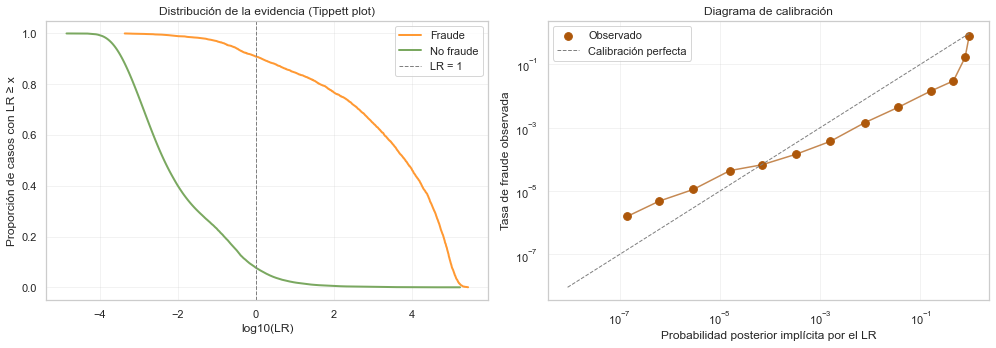

,bin,p_medio,tasa_empirica,n,fraudes
0,"(-4.871, -4.173]",9.215773e-09,0.000000,52091,0
1,"(-4.173, -3.486]",3.582901e-08,0.000000,2264090,0
2,"(-3.486, -2.799]",1.414352e-07,0.000002,6956126,11
3,"(-2.799, -2.111]",6.225983e-07,0.000005,6606349,32
4,"(-2.111, -1.424]",2.945801e-06,0.000011,3830960,43
5,"(-1.424, -0.737]",1.598314e-05,0.000044,2860952,127
6,"(-0.737, -0.0495]",7.009942e-05,0.000068,2906871,197
7,"(-0.0495, 0.638]",3.285112e-04,0.000145,1428754,207
8,"(0.638, 1.325]",1.585270e-03,0.000368,537772,198
9,"(1.325, 2.012]",7.679277e-03,0.001427,197677,282


<Figure size 432x288 with 0 Axes>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# TIPPETT PLOT

def tippett_plot(log_lr, y_true, ax=None):

    log_lr = np.asarray(log_lr, dtype=float)
    y_true = np.asarray(y_true)

    # Convertir ln(LR) -> log10(LR)
    log10_lr = log_lr / np.log(10)

    if ax is None:
        ax = plt.gca()

    # Fraude
    vals_fraude = np.sort(log10_lr[y_true == 1])

    if len(vals_fraude) > 0:
        prop_geq_fraude = (1 - np.arange(len(vals_fraude)) / len(vals_fraude))
        ax.plot(vals_fraude, prop_geq_fraude, linewidth=2, color="#FF9933", label="Fraude")

    # No fraude
    vals_no_fraude = np.sort(log10_lr[y_true == 0])

    if len(vals_no_fraude) > 0:
        prop_geq_no_fraude = (1 - np.arange(len(vals_no_fraude)) / len(vals_no_fraude))
        ax.plot(vals_no_fraude, prop_geq_no_fraude, linewidth=2, color="#7AA860", label="No fraude")

    # LR = 1 <=> log10(LR) = 0
    ax.axvline(0, linestyle="--", linewidth=1, color="gray", label="LR = 1")

    ax.set_xlabel("log10(LR)")
    ax.set_ylabel("Proporción de casos con LR ≥ x")
    ax.set_title("Distribución de la evidencia (Tippett plot)")
    ax.legend()
    ax.grid(True, alpha=0.25)

    return ax

# RELIABILITY DIAGRAM

def reliability_diagram_lr(
    lr_values,
    y_true,
    prior,
    n_bins=15,
    ax=None
):

    lr_values = np.asarray(lr_values, dtype=float)
    y_true = np.asarray(y_true)

    if ax is None:
        ax = plt.gca()

    # LR -> probabilidad posterior

    prior_odds = prior / (1 - prior)
    posterior_odds = lr_values * prior_odds
    p_implied = posterior_odds / (1 + posterior_odds)

    # log10(LR)
    log10_lr = np.log10(np.clip(lr_values, 1e-300, None))

    # Bins de igual ancho en log10(LR)
    bins = pd.cut(log10_lr, bins=n_bins, duplicates="drop")
    d = pd.DataFrame({"log10_LR": log10_lr, "p_implied": p_implied, "y": y_true, "bin": bins})
    summary = (d.groupby("bin", observed=True)
        .agg(
            log10_LR_medio=("log10_LR", "mean"),
            p_medio=("p_implied", "mean"),
            tasa_empirica=("y", "mean"),
            n=("y", "size"),
            fraudes=("y", "sum")
        )
        .reset_index())

    summary_plot = summary[(summary["p_medio"] > 0) & (summary["tasa_empirica"] > 0)].copy()


    ax.scatter(summary_plot["p_medio"], summary_plot["tasa_empirica"], color="#AD570A", s=60, label="Observado")
    ax.plot(summary_plot["p_medio"], summary_plot["tasa_empirica"], color="#AD570A", alpha=0.7)

    # Escala logarítmica
    ax.set_xscale("log")
    ax.set_yscale("log")

    # Línea de calibración perfecta
    min_val = min(summary.loc[summary["p_medio"] > 0, "p_medio"].min(), summary.loc[summary["tasa_empirica"] > 0, "tasa_empirica"].min())
    max_val = max(summary["p_medio"].max(), summary["tasa_empirica"].max())

    ax.plot([min_val, max_val], [min_val, max_val], "--", color="gray", linewidth=1, label="Calibración perfecta")

    ax.set_xlabel("Probabilidad posterior implícita por el LR")
    ax.set_ylabel("Tasa de fraude observada")
    ax.set_title("Diagrama de calibración")
    ax.legend()
    ax.grid(True, alpha=0.25)

    return ax, summary


# GENERAR LOS DOS GRÁFICOS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Tippett

tippett_plot(test_df["log_LR"].values, test_df["TX_FRAUD"].values, ax=axes[0])

_, summary_reliability = reliability_diagram_lr(test_df["LR"].values, test_df["TX_FRAUD"].values, prior=prior_test, n_bins=15, ax=axes[1])


plt.tight_layout()
plt.show()

# TABLA DEL RELIABILITY DIAGRAM

display(summary_reliability[["bin", "p_medio", "tasa_empirica", "n", "fraudes"]])

plt.tight_layout()
plt.savefig('tipplett_plot_calibracion.pdf', dpi=300, bbox_inches='tight')
plt.savefig('tipplett_plot_calibracion.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# CLLR

def cllr(lr, y):

    lr = np.asarray(lr, dtype=float)
    y = np.asarray(y)

    tp = (np.mean(np.log2(1 + 1 / lr[y == 1]))
        if (y == 1).any()
        else 0)

    td = (np.mean(np.log2(1 + lr[y == 0]))
        if (y == 0).any()
        else 0)

    return 0.5 * (tp + td)


cllr_global = cllr(test_df['LR'].values, test_df['TX_FRAUD'].values)

# RESULTADOS

print("\n" + "=" * 70)
print("RESULTADO FINAL")
print("=" * 70)

# DISTRIBUCIÓN DEL TEST POR ESCENARIO

print("\n" + "=" * 70)
print("TEST POR ESCENARIO")
print("=" * 70)


resumen_escenario = (test_df.groupby('TX_FRAUD_SCENARIO')
    .agg(
        OBSERVACIONES=('TX_FRAUD', 'size'),
        FRAUDES=('TX_FRAUD', 'sum'),
        PRIOR=('TX_FRAUD', 'mean'),
        MEDIANA_LOG_LR=('log_LR', 'median'),
        MEDIA_LOG_LR=('log_LR', 'mean'),
        MEDIANA_LR=('LR', 'median'),
        MEDIA_LR=('LR', 'mean')).reset_index())


print(resumen_escenario.to_string(index=False))

# CLLR POR ESCENARIO

print("\n" + "=" * 70)
print("CLLR POR ESCENARIO")
print("=" * 70)


resultados_cllr_escenario = []


for escenario, grupo in test_df.groupby(
    'TX_FRAUD_SCENARIO'):

    if (grupo['TX_FRAUD'].nunique() < 2):
        continue

    valor_cllr = cllr(grupo['LR'].values, grupo['TX_FRAUD'].values)

    resultados_cllr_escenario.append((escenario, len(grupo), grupo['TX_FRAUD'].sum(), valor_cllr))

cllr_escenario_df = pd.DataFrame(resultados_cllr_escenario, columns=['TX_FRAUD_SCENARIO', 'N', 'FRAUDES', 'CLLR'])

print(cllr_escenario_df.to_string(index=False))

# CLLR POR RÉGIMEN

print("\n" + "=" * 70)
print("CLLR POR RÉGIMEN")
print("=" * 70)

resultados_cllr_regimen = []


for regimen, grupo in test_df.groupby('REGIMEN'):

    if (grupo['TX_FRAUD'].nunique() < 2):
        continue

    valor_cllr = cllr(grupo['LR'].values, grupo['TX_FRAUD'].values)

    resultados_cllr_regimen.append(
        (regimen,
            grupo['TX_DATETIME'].min(),
            grupo['TX_DATETIME'].max(),
            len(grupo),
            grupo['TX_FRAUD'].sum(),
            grupo['TX_FRAUD'].mean(),
            valor_cllr))


cllr_regimen_df = pd.DataFrame(resultados_cllr_regimen, columns=['REGIMEN', 'FECHA_INICIO', 'FECHA_FIN', 'N', 'FRAUDES', 'PRIOR', 'CLLR'])

print(cllr_regimen_df.to_string(index=False))

# CLLR POR DÍA


def calcular_cllr_diario(grupo):

    if grupo['TX_FRAUD'].nunique() < 2:
        return np.nan

    return cllr(grupo['LR'].values, grupo['TX_FRAUD'].values)


cllr_diario_df = (test_df.groupby('TX_DATETIME').apply(calcular_cllr_diario).reset_index(name='CLLR'))


# TABLA FINAL ÚTIL PARA ANÁLISIS

tabla_diaria = (
    test_df
    .groupby(
        [
            'TX_DATETIME',
            'REGIMEN',
            'ES_TRANSICION'
        ]
    )
    .agg(
        N=('TX_FRAUD', 'size'),
        FRAUDES=('TX_FRAUD', 'sum'),
        PRIOR=('TX_FRAUD', 'mean'),

        FRAUDE_ESC2=(
            'FRAUDE_TEST_ESC2',
            'first'
        ),

        FRAUDE_ESC3=(
            'FRAUDE_TEST_ESC3',
            'first'
        ),

        MEDIANA_LOG_LR=(
            'log_LR',
            'median'
        ),

        MEDIA_LOG_LR=(
            'log_LR',
            'mean'
        ),

        MEDIANA_LR=(
            'LR',
            'median'
        )
    )
    .reset_index()
)


tabla_diaria = tabla_diaria.merge(cllr_diario_df, on='TX_DATETIME', how='left')


RESULTADO FINAL

TEST POR ESCENARIO
 TX_FRAUD_SCENARIO  OBSERVACIONES  FRAUDES  PRIOR  MEDIANA_LOG_LR  MEDIA_LOG_LR  MEDIANA_LR     MEDIA_LR
                 0       27781189        0    0.0       -5.417854     -4.670175    0.004437    11.925814
                 3           4709     4709    1.0        8.842773      7.391674 6924.169922 31330.558594

CLLR POR ESCENARIO
Empty DataFrame
Columns: [TX_FRAUD_SCENARIO, N, FRAUDES, CLLR]
Index: []

CLLR POR RÉGIMEN
  REGIMEN FECHA_INICIO  FECHA_FIN        N  FRAUDES    PRIOR     CLLR
periodo_4   2019-01-02 2019-06-30 27785898     4709 0.000169 0.316027

OBJETOS DISPONIBLES

resultados_df
    Todos los scores out-of-sample, antes de calibración.

calib_df
    Pool utilizado para calibrar Platt.

test_df
    Test con raw_score, log_LR y LR.

resumen_regimen
    Resumen de cada régimen temporal.

resumen_escenario
    Distribución de LR por escenario de fraude.

cllr_escenario_df
    Cllr por escenario.

cllr_regimen_df
    Cllr por régimen temp

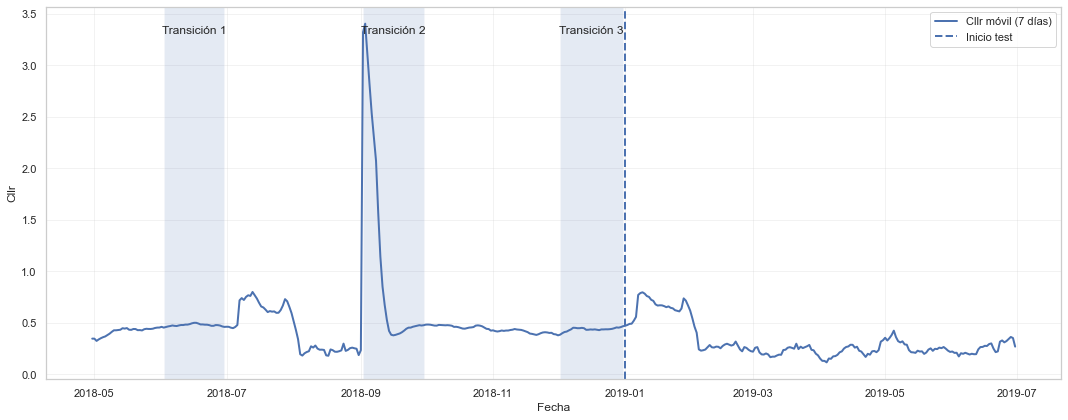

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(15, 6))

plot_df = resultados_por_ventana[30]["cllr_historico"].sort_values("TX_DATETIME")

# Cllr móvil
ax.plot(plot_df["TX_DATETIME"], plot_df["CLLR_7D"], linewidth=2, label="Cllr móvil (7 días)")

# TRANSICIONES

transiciones = [("2018-06-02", "2018-06-30"), ("2018-09-02", "2018-09-30"), ("2018-12-02", "2018-12-31")]

for i, (inicio, fin) in enumerate(transiciones, 1):
    ax.axvspan(pd.Timestamp(inicio), pd.Timestamp(fin), alpha=0.15)
    ax.text(pd.Timestamp(inicio) + (pd.Timestamp(fin) - pd.Timestamp(inicio)) / 2, 0.95, f"Transición {i}", transform=ax.get_xaxis_transform(), ha="center", va="top")

ax.axvline(pd.Timestamp("2019-01-01"), linestyle="--", linewidth=2, label="Inicio test")

ax.set_xlabel("Fecha")
ax.set_ylabel("Cllr")
ax.grid(True, alpha=0.25)
ax.legend()

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('evolucion_temporal_cllr.pdf', dpi=300, bbox_inches='tight')
plt.savefig('evolucion_temporal_cllr.png', dpi=300, bbox_inches='tight')
plt.show()

In [57]:
transiciones = {
    "Transición 1": (
        pd.Timestamp("2018-06-02"),
        pd.Timestamp("2018-06-30")
    ),
    "Transición 2": (
        pd.Timestamp("2018-09-02"),
        pd.Timestamp("2018-09-30")
    ),
    "Transición 3": (
        pd.Timestamp("2018-12-02"),
        pd.Timestamp("2018-12-31")
    )
}

In [ ]:
VENTANA = 30

with open(f"historico_ventana_{VENTANA}.pkl", "rb") as f:
    historico_df = pickle.load(f)

resultados_transiciones = []

for nombre, (inicio, fin) in transiciones.items():

    inicio_antes = inicio - pd.Timedelta(days=VENTANA)
    fin_despues = fin + pd.Timedelta(days=VENTANA)

    # Definir período

    historico_df["PERIODO_TRANSICION"] = np.select(
        [
            (
                (historico_df["TX_DATETIME"] >= inicio_antes) &
                (historico_df["TX_DATETIME"] < inicio)
            ),
            (
                (historico_df["TX_DATETIME"] >= inicio) &
                (historico_df["TX_DATETIME"] <= fin)
            ),
            (
                (historico_df["TX_DATETIME"] > fin) &
                (historico_df["TX_DATETIME"] <= fin_despues)
            )
        ],
        [
            "Antes",
            "Transición",
            "Después"
        ],
        default=np.nan
    )

    # Solo escenarios de fraude

    tmp = historico_df[historico_df["PERIODO_TRANSICION"].isin(["Antes", "Transición", "Después"]) & historico_df["TX_FRAUD_SCENARIO"].isin([2, 3]) & (historico_df["TX_FRAUD"] == 1)].copy()

    # Resumen

    resumen = (
        tmp
        .groupby(
            [
                "PERIODO_TRANSICION",
                "TX_FRAUD_SCENARIO"
            ]
        )
        .agg(
            N=("LR", "size"),
            MEDIANA_LR=("LR", "median"),
            MEDIA_LR=("LR", "mean"),
            MEDIANA_LOG_LR=("log_LR", "median"),
            MEDIA_LOG_LR=("log_LR", "mean")
        ).reset_index())
    resumen["TRANSICION"] = nombre
    resultados_transiciones.append(resumen)

lr_transiciones_df = pd.concat(resultados_transiciones, ignore_index=True)

lr_transiciones_df = lr_transiciones_df[["TRANSICION","PERIODO_TRANSICION","TX_FRAUD_SCENARIO","N","MEDIANA_LOG_LR","MEDIA_LOG_LR","MEDIANA_LR","MEDIA_LR"]]

lr_transiciones_df

,TRANSICION,PERIODO_TRANSICION,TX_FRAUD_SCENARIO,N,MEDIANA_LOG_LR,MEDIA_LOG_LR,MEDIANA_LR,MEDIA_LR
0,Transición 1,Antes,2,26121,2.581290,2.423171,13.214168,28.187311
1,Transición 1,Después,3,833,4.406314,3.839116,81.966766,3399.204102
2,Transición 1,Transición,2,25265,2.471821,2.301730,11.843993,19.350811
3,Transición 1,Transición,3,825,1.198608,1.937810,3.315498,167.434525
4,Transición 2,Antes,3,779,9.567382,8.047190,14290.951172,32583.974609
5,Transición 2,Después,2,25925,2.386931,2.249712,10.880056,17.732916
6,Transición 2,Transición,2,24996,2.110260,1.080863,8.250384,12.662160
7,Transición 2,Transición,3,741,4.042686,3.599867,56.979210,3591.083984
8,Transición 3,Antes,2,25508,2.683175,2.512184,14.631469,22.546701
9,Transición 3,Después,3,821,5.671108,4.376390,290.356018,5190.279785


In [ ]:
lr_transiciones_df[["TRANSICION","PERIODO_TRANSICION","TX_FRAUD_SCENARIO","N","MEDIANA_LOG_LR"]]

,TRANSICION,PERIODO_TRANSICION,TX_FRAUD_SCENARIO,N,MEDIANA_LOG_LR
0,Transición 1,Antes,2,26121,2.581290
1,Transición 1,Después,3,833,4.406314
2,Transición 1,Transición,2,25265,2.471821
3,Transición 1,Transición,3,825,1.198608
4,Transición 2,Antes,3,779,9.567382
5,Transición 2,Después,2,25925,2.386931
6,Transición 2,Transición,2,24996,2.110260
7,Transición 2,Transición,3,741,4.042686
8,Transición 3,Antes,2,25508,2.683175
9,Transición 3,Después,3,821,5.671108


In [ ]:
fraudes = historico_df[historico_df["TX_FRAUD"] == 1].copy()
loglr_diario = (fraudes.groupby("TX_DATETIME").agg(MEDIANA_LOG_LR=("log_LR", "median"), N_FRAUDES=("log_LR", "size")).reset_index())
loglr_diario.head()

,TX_DATETIME,MEDIANA_LOG_LR,N_FRAUDES
0,2018-04-30,3.533224,856
1,2018-05-01,3.680378,853
2,2018-05-02,3.644483,789
3,2018-05-03,3.139769,858
4,2018-05-04,3.223542,832


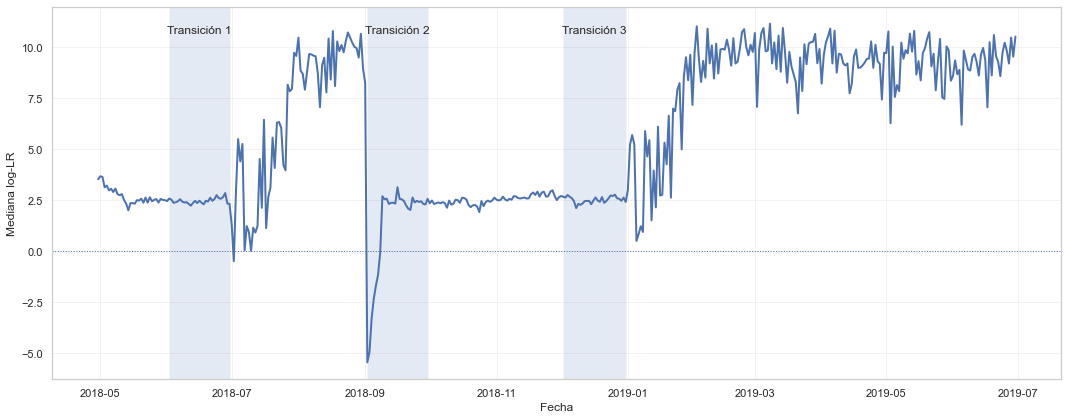

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(loglr_diario["TX_DATETIME"], loglr_diario["MEDIANA_LOG_LR"], linewidth=2)

# Marcar transiciones
for nombre, (inicio, fin) in transiciones.items():
    ax.axvspan(inicio, fin, alpha=0.15)
    ax.text(inicio + (fin - inicio) / 2, 0.95, nombre, transform=ax.get_xaxis_transform(), ha="center", va="top")

ax.axhline(0, linestyle=":", linewidth=1)
ax.set_xlabel("Fecha")
ax.set_ylabel("Mediana log-LR")
ax.grid(True, alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('mediana_diaria_loglr.pdf', dpi=300, bbox_inches='tight')
plt.savefig('mediana_diaria_loglr.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
loglr_escenario = (historico_df[(historico_df["TX_FRAUD"] == 1) & (historico_df["TX_FRAUD_SCENARIO"].isin([2, 3]))].groupby(["TX_DATETIME","TX_FRAUD_SCENARIO"]).agg(MEDIANA_LOG_LR=("log_LR", "median"), N_FRAUDES=("log_LR", "size")).reset_index())

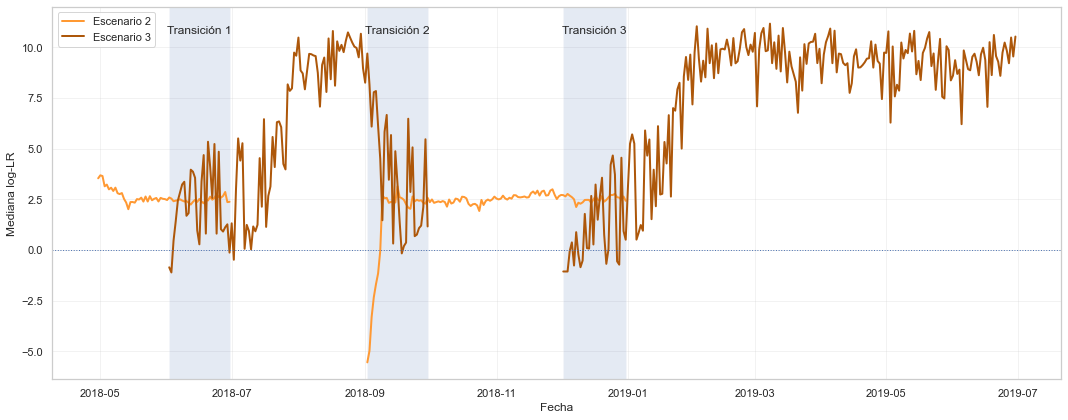

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

# Colores fijos por escenario
colores = {
    2: "#FF9933",
    3: "#AD570A"
}

fig, ax = plt.subplots(figsize=(15, 6))

for escenario in [2, 3]:

    tmp = (loglr_escenario[loglr_escenario["TX_FRAUD_SCENARIO"] == escenario].sort_values("TX_DATETIME").copy())

    # Detectar huecos temporales
    tmp["gap"] = tmp["TX_DATETIME"].diff().dt.days > 1
    tmp["tramo"] = tmp["gap"].cumsum()

    # Graficar cada tramo por separado
    for j, (_, tramo) in enumerate(tmp.groupby("tramo")):

        ax.plot(tramo["TX_DATETIME"], tramo["MEDIANA_LOG_LR"], linewidth=2, color=colores[escenario],
            # Mostrar una sola vez cada escenario
            label=f"Escenario {escenario}" if j == 0 else None)

# TRANSICIONES

for nombre, (inicio, fin) in transiciones.items():
    ax.axvspan(inicio, fin, alpha=0.15)
    ax.text(inicio + (fin - inicio) / 2, 0.95, nombre, transform=ax.get_xaxis_transform(), ha="center", va="top")

ax.axhline(0, linestyle=":", linewidth=1)


ax.set_xlabel("Fecha")
ax.set_ylabel("Mediana log-LR")
ax.legend()
ax.grid(True, alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('mediana_diaria_loglr_escenario.pdf', dpi=300, bbox_inches='tight')
plt.savefig('mediana_diaria_loglr_escenario.png', dpi=300, bbox_inches='tight')
plt.show()

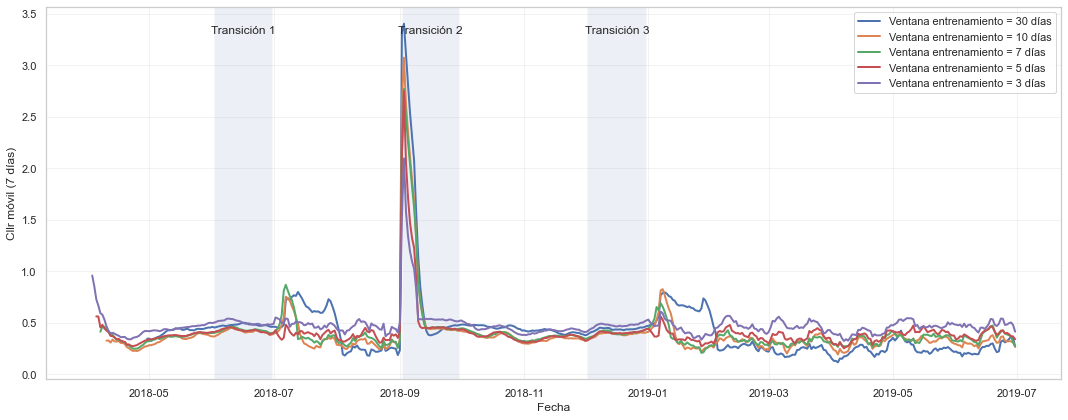

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(15, 6))

for ventana, resultado in resultados_por_ventana.items():
    datos = (resultado["cllr_historico"].sort_values("TX_DATETIME"))
    ax.plot(datos["TX_DATETIME"], datos["CLLR_7D"], linewidth=2, label=f"Ventana entrenamiento = {ventana} días")

# Transiciones

for nombre, (inicio, fin) in transiciones.items():
    ax.axvspan(inicio, fin, alpha=0.10)
    ax.text(inicio + (fin - inicio) / 2, 0.95, nombre, transform=ax.get_xaxis_transform(), ha="center", va="top")

ax.set_xlabel("Fecha")
ax.set_ylabel("Cllr móvil (7 días)")
ax.legend()
ax.grid(True, alpha=0.25)

plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('evolucion_cllr_ventana.pdf', dpi=300, bbox_inches='tight')
plt.savefig('evolucion_cllr_ventana.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import numpy as np
import pandas as pd

filas = []

transiciones_lista = list(transiciones.items())

for ventana, info in resultados_por_ventana.items():
    
    datos = info["cllr_historico"].sort_values("TX_DATETIME").copy()
    datos["TX_DATETIME"] = pd.to_datetime(datos["TX_DATETIME"])

    for i, (nombre, (inicio, fin)) in enumerate(transiciones_lista):

        # BASELINE

        previo = datos[(datos["TX_DATETIME"] >= inicio - pd.Timedelta(days=30)) & (datos["TX_DATETIME"] < inicio)]
        baseline = previo["CLLR_7D"].median()

        # HORIZONTE DE ANÁLISIS
        
        if i < len(transiciones_lista) - 1:

            siguiente_inicio = transiciones_lista[i + 1][1][0]
            post = datos[(datos["TX_DATETIME"] >= inicio) & (datos["TX_DATETIME"] < siguiente_inicio)]

        else:
            # Para la última transición usamos todo lo restante
            post = datos[datos["TX_DATETIME"] >= inicio]

        # MÁXIMO DETERIORO

        cllr_max = post["CLLR_7D"].max()
        fecha_max = post.loc[post["CLLR_7D"].idxmax(), "TX_DATETIME"]
        deterioro = cllr_max - baseline

        # UMBRAL DE RECUPERACIÓN

        umbral = baseline * 1.10
        despues_max = post[post["TX_DATETIME"] > fecha_max].copy()
        recuperacion = despues_max[despues_max["CLLR_7D"] <= umbral]

        # FECHA DE RECUPERACIÓN

        if not recuperacion.empty:

            fecha_recuperacion = (recuperacion.iloc[0]["TX_DATETIME"])
            dias_recuperacion = (fecha_recuperacion - fecha_max).days

        else:

            fecha_recuperacion = pd.NaT
            dias_recuperacion = np.nan

        filas.append({
            "VENTANA": ventana,
            "TRANSICION": nombre,
            "CLLR_PREVIO": baseline,
            "UMBRAL_RECUPERACION": umbral,
            "CLLR_MAX": cllr_max,
            "DETERIORO": deterioro,
            "FECHA_MAX": fecha_max,
            "FECHA_RECUPERACION": fecha_recuperacion,
            "DIAS_RECUPERACION": dias_recuperacion
        })


resumen_adaptacion = pd.DataFrame(filas)
resumen_adaptacion = resumen_adaptacion.sort_values(["TRANSICION", "VENTANA"], ascending=[True, False])
resumen_adaptacion

,VENTANA,TRANSICION,CLLR_PREVIO,UMBRAL_RECUPERACION,CLLR_MAX,DETERIORO,FECHA_MAX,FECHA_RECUPERACION,DIAS_RECUPERACION
0,30,Transición 1,0.430375,0.473413,0.796874,0.366499,2018-07-13,2018-08-02,20.0
3,10,Transición 1,0.365491,0.402040,0.750589,0.385098,2018-07-07,2018-07-14,7.0
6,7,Transición 1,0.365399,0.401939,0.866484,0.501084,2018-07-07,2018-07-13,6.0
9,5,Transición 1,0.375935,0.413528,0.478515,0.102580,2018-07-07,2018-07-09,2.0
12,3,Transición 1,0.450094,0.495104,0.549516,0.099421,2018-07-02,2018-07-09,7.0
1,30,Transición 2,0.233053,0.256358,3.401792,3.168739,2018-09-03,NaT,NaN
4,10,Transición 2,0.288415,0.317256,3.071498,2.783083,2018-09-03,2018-10-29,56.0
7,7,Transición 2,0.316215,0.347836,2.769114,2.452899,2018-09-03,2018-10-28,55.0
10,5,Transición 2,0.357942,0.393736,2.748088,2.390146,2018-09-03,2018-10-07,34.0
13,3,Transición 2,0.450847,0.495931,2.093748,1.642901,2018-09-03,2018-10-04,31.0


In [ ]:
despues_max = post[post["TX_DATETIME"] > fecha_max].copy()
despues_max["RECUPERADO"] = (despues_max["CLLR_7D"] <= umbral)

# Recuperación sostenida durante 3 días
despues_max["RECUPERADO_3D"] = (despues_max["RECUPERADO"].rolling(3).sum().eq(3))

candidatos = despues_max[despues_max["RECUPERADO_3D"]]

if not candidatos.empty:

    idx_fin = candidatos.index[0]
    pos_fin = despues_max.index.get_loc(idx_fin)
    pos_inicio = pos_fin - 2
    fecha_recuperacion = (despues_max.iloc[pos_inicio]["TX_DATETIME"])
    dias_recuperacion = (fecha_recuperacion - fecha_max).days

else:

    fecha_recuperacion = pd.NaT
    dias_recuperacion = np.nan

In [ ]:
resumen_adaptacion[["VENTANA", "TRANSICION", "CLLR_PREVIO", "CLLR_MAX", "DETERIORO", "FECHA_MAX", "FECHA_RECUPERACION", "DIAS_RECUPERACION"]]

,VENTANA,TRANSICION,CLLR_PREVIO,CLLR_MAX,DETERIORO,FECHA_MAX,FECHA_RECUPERACION,DIAS_RECUPERACION
0,30,Transición 1,0.430375,0.796874,0.366499,2018-07-13,2018-08-02,20.0
3,10,Transición 1,0.365491,0.750589,0.385098,2018-07-07,2018-07-14,7.0
6,7,Transición 1,0.365399,0.866484,0.501084,2018-07-07,2018-07-13,6.0
9,5,Transición 1,0.375935,0.478515,0.102580,2018-07-07,2018-07-09,2.0
12,3,Transición 1,0.450094,0.549516,0.099421,2018-07-02,2018-07-09,7.0
1,30,Transición 2,0.233053,3.401792,3.168739,2018-09-03,NaT,NaN
4,10,Transición 2,0.288415,3.071498,2.783083,2018-09-03,2018-10-29,56.0
7,7,Transición 2,0.316215,2.769114,2.452899,2018-09-03,2018-10-28,55.0
10,5,Transición 2,0.357942,2.748088,2.390146,2018-09-03,2018-10-07,34.0
13,3,Transición 2,0.450847,2.093748,1.642901,2018-09-03,2018-10-04,31.0


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


transiciones_lr = {

    "Transición 1": {
        "inicio": pd.Timestamp("2018-06-01"),
        "fin": pd.Timestamp("2018-06-30"),
        "escenario_entrante": 3,
        "fin_estable": pd.Timestamp("2018-08-31")
    },

    "Transición 2": {
        "inicio": pd.Timestamp("2018-09-01"),
        "fin": pd.Timestamp("2018-09-30"),
        "escenario_entrante": 2,
        "fin_estable": pd.Timestamp("2018-11-30")
    },

    "Transición 3": {
        "inicio": pd.Timestamp("2018-12-01"),
        "fin": pd.Timestamp("2018-12-31"),
        "escenario_entrante": 3,
        "fin_estable": pd.Timestamp("2019-02-28")
    }
}

In [ ]:
def obtener_loglr_diario(df, escenario):
    
    aux = df[(df["TX_FRAUD"] == 1) & (df["TX_FRAUD_SCENARIO"] == escenario)].copy()
    aux["TX_DATETIME"] = pd.to_datetime(aux["TX_DATETIME"])
    diario = (aux.groupby("TX_DATETIME").agg(MEDIANA_LOG_LR=("log_LR", "median"), N_FRAUDES=("TX_FRAUD", "size")).reset_index().sort_values("TX_DATETIME"))

    return diario

In [ ]:
def calcular_nivel_estable(diario, fin_transicion, fin_estable, dias_referencia=30):

    periodo_post = diario[(diario["TX_DATETIME"] > fin_transicion) & (diario["TX_DATETIME"] <= fin_estable)].copy()

    if periodo_post.empty:
        return np.nan

    fecha_inicio_referencia = (periodo_post["TX_DATETIME"].max() - pd.Timedelta(days=dias_referencia - 1))
    referencia = periodo_post[periodo_post["TX_DATETIME"] >= fecha_inicio_referencia]

    if referencia.empty:
        return np.nan

    return referencia["MEDIANA_LOG_LR"].median()

In [28]:
TOLERANCIA_LOG_LR = 0.5
DIAS_CONSECUTIVOS = 3

In [ ]:
def encontrar_estabilizacion(diario, inicio_transicion, nivel_estable, tolerancia=0.5, dias_consecutivos=3):

    post = diario[diario["TX_DATETIME"] >= inicio_transicion].copy()
    post["DIFERENCIA_ESTABLE"] = np.abs(post["MEDIANA_LOG_LR"] - nivel_estable)
    post["DENTRO_RANGO"] = (post["DIFERENCIA_ESTABLE"] <= tolerancia)

    dentro = post["DENTRO_RANGO"].to_numpy()

    for i in range(len(dentro) - dias_consecutivos + 1):
        if dentro[i:i + dias_consecutivos].all():
            return post.iloc[i]["TX_DATETIME"]

    return pd.NaT

In [ ]:
resultados_adaptacion_lr = []

for ventana in VENTANAS:

    with open(f"historico_ventana_{ventana}.pkl", "rb") as f:
        df_lr = pickle.load(f)

    for nombre, info in transiciones_lr.items():
        escenario = info["escenario_entrante"]
        inicio = info["inicio"]
        fin = info["fin"]
        fin_estable = info["fin_estable"]

        # Mediana diaria del escenario entrante
        diario = obtener_loglr_diario(df_lr, escenario)

        # Nivel estable posterior
        nivel_estable = calcular_nivel_estable(diario, fin_transicion=fin, fin_estable=fin_estable, dias_referencia=30)

        # Fecha de estabilización
        fecha_estabilizacion = encontrar_estabilizacion(diario, inicio_transicion=inicio, nivel_estable=nivel_estable, tolerancia=0.5, dias_consecutivos=3)

        # Días desde inicio de transición
        if pd.notna(fecha_estabilizacion):
            dias_adaptacion = (fecha_estabilizacion - inicio).days
        else:
            dias_adaptacion = np.nan

        # Mediana durante la transición
        durante = diario[(diario["TX_DATETIME"] >= inicio) & (diario["TX_DATETIME"] <= fin)]

        mediana_durante = (
            durante["MEDIANA_LOG_LR"].median()
            if not durante.empty
            else np.nan)

        # Resultado
        resultados_adaptacion_lr.append({
            "VENTANA": ventana,
            "TRANSICION": nombre,
            "ESCENARIO_ENTRANTE": escenario,
            "LOG_LR_DURANTE": mediana_durante,
            "LOG_LR_ESTABLE": nivel_estable,
            "FECHA_ESTABILIZACION": fecha_estabilizacion,
            "DIAS_ADAPTACION": dias_adaptacion})

    del df_lr
    gc.collect()

In [ ]:
adaptacion_lr_df = pd.DataFrame(resultados_adaptacion_lr)
adaptacion_lr_df = (adaptacion_lr_df.sort_values(["TRANSICION", "VENTANA"], ascending=[True, False]))
display(adaptacion_lr_df)

,VENTANA,TRANSICION,ESCENARIO_ENTRANTE,LOG_LR_DURANTE,LOG_LR_ESTABLE,FECHA_ESTABILIZACION,DIAS_ADAPTACION
0,30,Transición 1,3,1.818878,9.616087,2018-08-06,66
3,10,Transición 1,3,2.702717,6.936196,2018-07-22,51
6,7,Transición 1,3,2.209461,5.899934,2018-07-13,42
9,5,Transición 1,3,1.827432,5.389057,2018-07-05,34
12,3,Transición 1,3,1.607920,4.128810,2018-07-04,33
1,30,Transición 2,2,2.368316,2.664706,2018-09-09,8
4,10,Transición 2,2,2.535700,2.991565,2018-09-09,8
7,7,Transición 2,2,2.199746,2.614646,2018-09-08,7
10,5,Transición 2,2,2.121726,2.515639,2018-09-04,3
13,3,Transición 2,2,1.568969,1.941659,2018-09-04,3


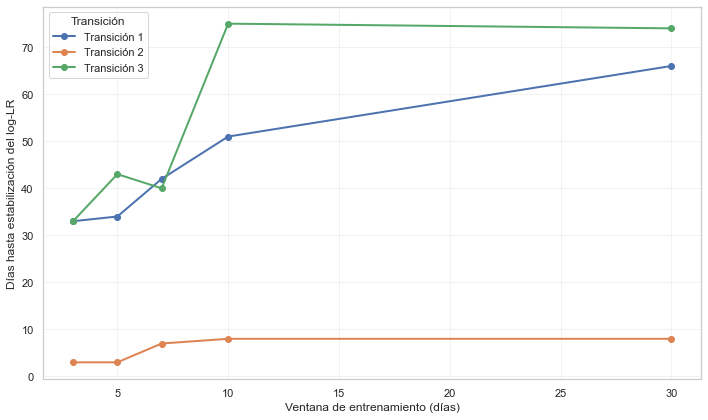

: 

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(10, 6))

for transicion in adaptacion_lr_df["TRANSICION"].unique():
    aux = (adaptacion_lr_df[adaptacion_lr_df["TRANSICION"] == transicion].sort_values("VENTANA" ))
    ax.plot(aux["VENTANA"], aux["DIAS_ADAPTACION"], marker="o", linewidth=2, label=transicion)

ax.set_xlabel("Ventana de entrenamiento (días)")
ax.set_ylabel("Días hasta estabilización del log-LR")
ax.legend(title="Transición")
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig('velocidad_adaptacion_lr.pdf', dpi=300, bbox_inches='tight')
plt.savefig('velocidad_adaptacion_lr.png', dpi=300, bbox_inches='tight')
plt.show()